# Model B: LVI Trend Forecast (Part B)

Goal: forecast the CBSL Land Valuation Indicator (LVI) for Colombo, half-yearly.
This trend is later multiplied with the Part A base price (in PP2).

Steps:
1. Load and look at the LVI data
2. Compare simple models: Naive, Drift, Linear, Holt
3. Check them with a fixed split and a rolling backtest
4. Pick one model and forecast up to 2028-H2, with a low/mid/high range


In [1]:
# Import the libraries we need
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our helper file is in the src folder (two levels up)
sys.path.append("../../src")
from load_cbsl import load_lvi_half_yearly


In [2]:
# Load the raw CBSL LVI file (it is an HTML table saved as .xls)
lvi_all = load_lvi_half_yearly("../../data/raw/cbsl_half_yearly_dataset.xls")

# Show the first and last rows
display(lvi_all.head(3))
display(lvi_all.tail(3))


,period,Overall,Residential,Commercial,Industrial
0,2017-H1,100.0,100.0,100.0,100.0
1,2017-H2,107.0,106.8,107.0,107.2
2,2018-H1,114.7,114.3,114.7,115.1


,period,Overall,Residential,Commercial,Industrial
15,2024-H2,236.8,242.9,234.1,233.2
16,2025-H1,256.4,266.9,254.3,248.0
17,2025-H2,NaN,NaN,NaN,NaN


In [3]:
# Keep only the Overall LVI and drop the empty 2025-H2 row
lvi = lvi_all[["period", "Overall"]].dropna().reset_index(drop=True)
lvi.columns = ["period", "lvi"]

# Add a simple time number: 0, 1, 2, ... (one step = one half-year)
lvi["t"] = range(len(lvi))

# Show size and the change from one half-year to the next
print("Number of points:", len(lvi))
lvi["change"] = lvi["lvi"].diff()
display(lvi)


Number of points: 17


,period,lvi,t,change
0,2017-H1,100.0,0,NaN
1,2017-H2,107.0,1,7.0
2,2018-H1,114.7,2,7.7
3,2018-H2,122.3,3,7.6
4,2019-H1,129.7,4,7.4
5,2019-H2,137.2,5,7.5
6,2020-H1,144.3,6,7.1
7,2020-H2,151.6,7,7.3
8,2021-H1,159.8,8,8.2
9,2021-H2,178.7,9,18.9


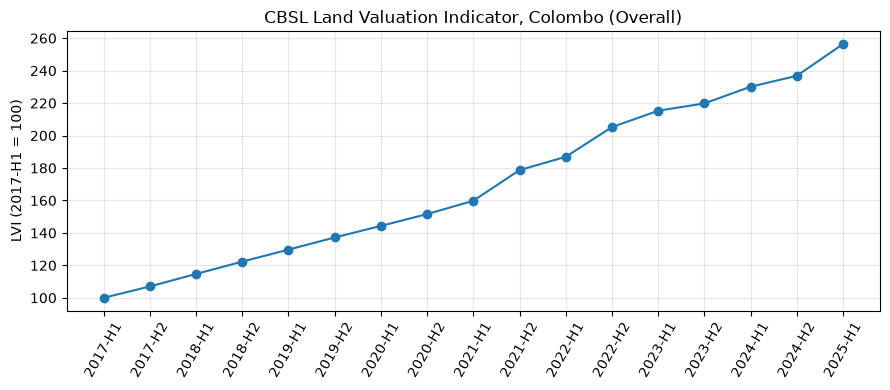

In [4]:
# Plot the LVI over time
plt.figure(figsize=(9, 4))
plt.plot(lvi["t"], lvi["lvi"], marker="o")

# Show the period names on the x axis
plt.xticks(lvi["t"], lvi["period"], rotation=60)
plt.ylabel("LVI (2017-H1 = 100)")
plt.title("CBSL Land Valuation Indicator, Colombo (Overall)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## What we see in the LVI data

- 17 half-yearly points, from 2017-H1 to 2025-H1 (2025-H2 is not published yet).
- The index grows almost in a straight line, but faster after 2021.
- With only 17 points, we must keep the models simple.


## Part 2: Simple forecasting models

Each model takes the past LVI values and forecasts the next `h` half-years.

- **Naive:** next values = last value (no growth). Only a baseline to beat.
- **Drift:** continue with the average change per half-year seen in the past.
- **Linear:** fit one straight line through all points and extend it.
- **Holt:** smooth level and trend (added in the next cell).


In [6]:
# Naive: repeat the last value
def forecast_naive(y, h):
    return np.repeat(y[-1], h)

# Drift: last value + average change per half-year
def forecast_drift(y, h):
    step = (y[-1] - y[0]) / (len(y) - 1)
    return y[-1] + step * np.arange(1, h + 1)

# Linear: fit a straight line on time and extend it
def forecast_linear(y, h):
    t = np.arange(len(y))
    slope, intercept = np.polyfit(t, y, 1)
    future_t = np.arange(len(y), len(y) + h)
    return intercept + slope * future_t

# Quick test: forecast the next 3 half-years from all 17 points
y_all = lvi["lvi"].values
for name, f in [("Naive", forecast_naive), ("Drift", forecast_drift), ("Linear", forecast_linear)]:
    print(name, np.round(f(y_all, 3), 1))


Naive [256.4 256.4 256.4]
Drift [266.2 276.  285.7]
Linear [258.5 268.3 278.1]


In [7]:
# Holt: keep a "level" and a "trend", and update them step by step.
# alpha controls how fast the level reacts, beta controls how fast the trend reacts.
def holt_run(y, alpha, beta):
    level, trend = y[0], y[1] - y[0]
    sse = 0.0
    for v in y[1:]:
        sse += (v - (level + trend)) ** 2          # one-step error
        new_level = alpha * v + (1 - alpha) * (level + trend)
        trend = beta * (new_level - level) + (1 - beta) * trend
        level = new_level
    return level, trend, sse

def forecast_holt(y, h):
    # Try many alpha/beta pairs and keep the pair with the smallest error
    grid = np.arange(0.1, 1.0, 0.1)
    best = None
    for a in grid:
        for b in grid:
            level, trend, sse = holt_run(y, a, b)
            if best is None or sse < best[0]:
                best = (sse, level, trend)
    _, level, trend = best
    return level + trend * np.arange(1, h + 1)

# Quick test: forecast the next 3 half-years from all 17 points
print("Holt", np.round(forecast_holt(y_all, 3), 1))


Holt [266.5 277.5 288.6]


In [8]:
# Fixed split: first 14 points for training, last 3 for testing
train = lvi["lvi"].values[:14]
test = lvi["lvi"].values[14:]
test_periods = lvi["period"].values[14:]

models = {
    "Naive": forecast_naive,
    "Drift": forecast_drift,
    "Linear": forecast_linear,
    "Holt": forecast_holt,
}

rows = []
preds = {}
for name, f in models.items():
    p = f(train, 3)
    preds[name] = p
    mape = np.mean(np.abs(test - p) / test) * 100   # average % error
    mae = np.mean(np.abs(test - p))                 # average error in index points
    rows.append({"model": name, "MAPE_%": round(mape, 2), "MAE_points": round(mae, 2)})

fixed_results = pd.DataFrame(rows).sort_values("MAPE_%").reset_index(drop=True)
display(fixed_results)
print("Test periods:", list(test_periods))


,model,MAPE_%,MAE_points
0,Holt,1.33,3.32
1,Drift,1.52,3.82
2,Linear,1.98,4.93
3,Naive,8.64,21.30


Test periods: ['2024-H1', '2024-H2', '2025-H1']


**Check 2: Rolling backtest.** This is a stronger check.

- Start with the first 8 points as training data.
- Forecast 1, 2 and 3 half-years ahead, and compare with the real values.
- Move one step forward (add one real point to training) and repeat until the data ends.

This gives 24 forecasts per model. We report the average % error (MAPE) for each model and for each horizon.


In [9]:
# Rolling backtest: train on y[:k], forecast up to 3 steps, compare with real values
y = lvi["lvi"].values
rows = []

for name, f in models.items():
    for k in range(8, len(y)):                 # k = number of training points
        h_max = min(3, len(y) - k)             # do not go past the end of the data
        p = f(y[:k], h_max)
        for h in range(1, h_max + 1):
            actual = y[k + h - 1]
            rows.append({
                "model": name,
                "train_end": lvi["period"][k - 1],
                "horizon": h,
                "ape_%": abs(actual - p[h - 1]) / actual * 100,
            })

roll = pd.DataFrame(rows)

# Overall average error per model
overall = roll.groupby("model")["ape_%"].agg(["mean", "count"]).round(2)
overall.columns = ["MAPE_%", "n_forecasts"]
display(overall.sort_values("MAPE_%"))

# Average error by horizon (1, 2, 3 half-years ahead)
by_h = roll.pivot_table(index="model", columns="horizon", values="ape_%").round(2)
by_h.columns = ["1 step", "2 steps", "3 steps"]
display(by_h.loc[overall.sort_values("MAPE_%").index])


,MAPE_%,n_forecasts
model,,
Drift,3.54,24
Holt,4.48,24
Linear,4.69,24
Naive,10.17,24


,1 step,2 steps,3 steps
model,,,
Drift,2.23,3.81,4.92
Holt,2.94,4.54,6.39
Linear,3.46,4.92,6.01
Naive,5.63,10.79,15.31


## Part 4: Pick the model and forecast

**Selection rule (decided before looking at the final forecast):** choose the model with the lowest MAPE in the rolling backtest. The fixed split has only 3 test points, so it is only a second check.

- Fixed split: Holt 1.33%, Drift 1.52% (close).
- Rolling backtest: Drift 3.54% is best (Holt 4.48%, Linear 4.69%).
- **Chosen model: Drift.**

**Forecast range.** A single number is too sure. We add a low/high range using the average backtest error per horizon (Drift: about 2.2%, 3.8%, 4.9% at 1, 2, 3 steps). The error grows roughly in a straight line with the horizon, so we extend it beyond 3 steps. This is a rough range, not a statistical guarantee.


In [10]:
# Pick the model with the lowest rolling MAPE
best_name = overall["MAPE_%"].idxmin()
best_f = models[best_name]
print("Chosen model:", best_name)

# Backtest error of the chosen model at horizon 1, 2, 3
err_h = roll[roll["model"] == best_name].groupby("horizon")["ape_%"].mean()
h_steps = err_h.index.values
# Error grows about linearly with horizon: fit error = k * horizon
k = (h_steps * err_h.values).sum() / (h_steps ** 2).sum()
print("Error grows about", round(k, 2), "% per half-year ahead")

# Forecast 7 half-years ahead (2025-H2 ... 2028-H2) using all 17 points
H = 7
mid = best_f(y_all, H)
err = k * np.arange(1, H + 1) / 100
periods = ["2025-H2", "2026-H1", "2026-H2", "2027-H1", "2027-H2", "2028-H1", "2028-H2"]

forecast = pd.DataFrame({
    "period": periods,
    "horizon": np.arange(1, H + 1),
    "low": np.round(mid * (1 - err), 1),
    "mid": np.round(mid, 1),
    "high": np.round(mid * (1 + err), 1),
})
display(forecast)


Chosen model: Drift
Error grows about 1.76 % per half-year ahead


,period,horizon,low,mid,high
0,2025-H2,1,261.5,266.2,270.9
1,2026-H1,2,266.2,276.0,285.7
2,2026-H2,3,270.7,285.7,300.8
3,2027-H1,4,274.7,295.5,316.3
4,2027-H2,5,278.4,305.3,332.1
5,2028-H1,6,281.8,315.0,348.3
6,2028-H2,7,284.9,324.8,364.8


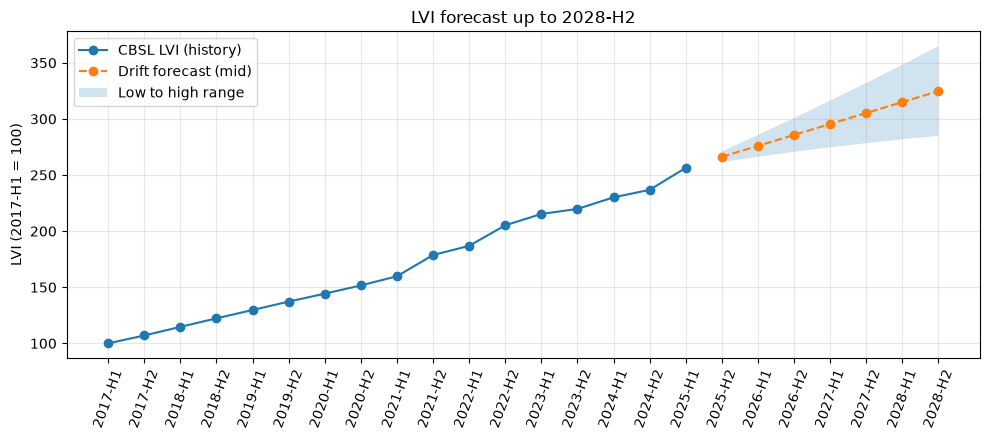

In [11]:
# Plot the history and the forecast with its range
plt.figure(figsize=(10, 4.5))

# History
plt.plot(lvi["t"], lvi["lvi"], marker="o", label="CBSL LVI (history)")

# Forecast: time numbers continue after the last history point
t_future = np.arange(len(lvi), len(lvi) + H)
plt.plot(t_future, forecast["mid"], marker="o", linestyle="--", label=f"{best_name} forecast (mid)")
plt.fill_between(t_future, forecast["low"], forecast["high"], alpha=0.2, label="Low to high range")

# Show period names on the x axis
all_periods = list(lvi["period"]) + periods
plt.xticks(range(len(all_periods)), all_periods, rotation=70)
plt.ylabel("LVI (2017-H1 = 100)")
plt.title("LVI forecast up to 2028-H2")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
import json, os

OUT = "../../reports/model_b/"
os.makedirs(OUT, exist_ok=True)

# Save the result tables
fixed_results.to_csv(OUT + "model_b_fixed_split_results.csv", index=False)
overall.to_csv(OUT + "model_b_rolling_results.csv")
by_h.to_csv(OUT + "model_b_rolling_by_horizon.csv")
forecast.to_csv(OUT + "model_b_lvi_forecast.csv", index=False)

# Save the small facts that Part A + Part B combine step (PP2) will need
info = {
    "chosen_model": best_name,
    "last_period": lvi["period"].iloc[-1],
    "last_lvi": float(lvi["lvi"].iloc[-1]),
    "drift_step_per_half_year": float((y_all[-1] - y_all[0]) / (len(y_all) - 1)),
    "error_pct_per_half_year": round(float(k), 2),
    "note": "LVI forecast from CBSL half-yearly data (17 points). Range = average rolling backtest error, not a statistical guarantee.",
}
with open(OUT + "model_b_info.json", "w") as f:
    json.dump(info, f, indent=2)

print("Saved to", OUT)
print(info)


Saved to ../../reports/model_b/
{'chosen_model': 'Drift', 'last_period': '2025-H1', 'last_lvi': 256.4, 'drift_step_per_half_year': 9.774999999999999, 'error_pct_per_half_year': 1.76, 'note': 'LVI forecast from CBSL half-yearly data (17 points). Range = average rolling backtest error, not a statistical guarantee.'}


## Summary and limitations

**Result.** Drift was the best model in the rolling backtest (MAPE 3.54%). Forecast for 2028-H2: about 325 (range 285 to 365), compared with 256.4 in 2025-H1.

**Limitations**
- Only 17 half-yearly points, so the evidence is thin and the fixed split (3 test points) is weak.
- Drift assumes the average growth continues. A change in the economy can break this.
- The range is the average backtest error extended past 3 steps. It is rough, not a statistical guarantee.
- The 2025-H1 value (256.4) had a big jump (+19.6), and the full-history drift is 9.77 per half-year while recent steps were higher. The forecast may be low if fast growth continues.
- LVI is an index for the Colombo district. We assume the same trend for all areas.

**Next (PP2).** Future price = Part A base price x (LVI_future / 256.4).
